In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

In [2]:
# 1. Imports and settings
from pathlib import Path
from copy import deepcopy
from datetime import datetime, timezone
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

archive_dir = Path('/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412')
steps_1_3_dir = archive_dir / 'diagnostic_steps_1_3' / 'run_01'
input_mode = 'core'                      # 'core' or 'steps_1_3'; no automatic fallback.
results_dir = archive_dir / 'diagnostic_steps_4_5' / 'run_01'
models_to_use = None                     # None = all matched models in the chosen input.
member_label_overrides = {}              # Same verified-label override format as steps 1–3.
identity_rtol, identity_atol = 2e-5, 1e-8
save_results, load_results, overwrite = False, False, False

# The same color limits are used across actual/substituted maps within a family.
# None includes the full displayed range; [0.25, 7.5] reproduces Figure 1 bounds.
substitution_vlims = None
plot_method, color_binning = 'pcolormesh', 'discrete'
cmap_name, central_longitude = 'cmr.fusion_r', 210
show_regions, save_figures, figure_dpi = True, False, 200

def mean_and_count(values):
    """Finite arithmetic mean over axis 0, retaining contributor counts."""
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    count, total = finite.sum(axis=0), np.where(finite, values, 0.).sum(axis=0)
    mean = np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)
    return mean, count

In [3]:
# 2. Load original archive members OR saved steps 1–3 members
# Only load trusted pickle-containing dictionaries. No saved aggregate is used.
if input_mode == 'core':
    input_dir = archive_dir
    names = ['member_values', 'observations', 'coordinates', 'model_names', 'member_ids',
             'quantity_info', 'sources', 'metadata']
    paths = {name: input_dir / ('overlap_' + name + '.npy') for name in names}
elif input_mode == 'steps_1_3':
    input_dir = steps_1_3_dir
    names = ['member_values', 'observations', 'coordinates', 'model_names', 'member_ids',
             'quantity_info', 'metadata']
    paths = {name: input_dir / ('diagnostic_' + name + '.npy') for name in names}
else:
    raise ValueError('input_mode must be core or steps_1_3.')
missing = [str(path) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError('Input files are missing. Check input_mode and its directory: ' + str(missing))
loaded = {name: np.load(path, allow_pickle=True).item() for name, path in paths.items()}
input_metadata = deepcopy(loaded['metadata'])
if input_mode == 'steps_1_3':
    loaded['sources'] = deepcopy(input_metadata['source_provenance'])
    loaded['metadata'] = deepcopy(input_metadata['source_metadata'])

# These aliases allow the familiar audit/reconstruction cells to work unchanged.
archive = {'overlap_' + name: value for name, value in loaded.items()}
source_values, source_observations = loaded['member_values'], loaded['observations']
source_coordinates, source_model_names = loaded['coordinates'], loaded['model_names']
source_member_ids, source_metadata = loaded['member_ids'], loaded['metadata']
historical_source = 'historical' if 'historical' in source_values else 'historical_matched'
print('Input:', input_mode, input_dir)
print('Available quantities:', list(loaded['quantity_info']))
display(pd.Series(source_metadata, name='saved setting').to_frame())

Input: core /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412
Available quantities: ['corr_Ti_Ri', 'corr_T_Ri', 'corr_Ti_R', 'corr_T_R', 'sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R', 'T_detrended', 'R_detrended', 'T_trend_in', 'R_trend_in', 'cov_Zi_R', 'cov_Ti_R', 'cov_T_Qi', 'cov_T_Ri', 'cov_Zi_Ri', 'cov_Ti_Qi', 'cov_Ti_Ri']


,saved setting
schema_version,1
created_utc,2026-09-11T21:55:18.708173+00:00
start_month,2000-03
end_month,2014-12
n_time,178
ddof,1
detrending_function,detrend_monthly_fast
detrending_source,"def detrend_monthly_fast(arr):\n """"""Detrend..."
preprocessing,User's monthwise detrend/deseasonalize; then c...
trend_in_series,Subtract each calendar month's mean within the...


In [4]:
# 3. Audit the chosen input and select explicit CanESM5 p2 labels
lat, lon = [np.asarray(source_coordinates[key], dtype=float) for key in ['lat', 'lon']]
times = np.asarray(source_coordinates['time']).astype('datetime64[M]')
expected_months = np.arange(np.datetime64('2000-03'), np.datetime64('2015-01'), dtype='datetime64[M]')
if not np.array_equal(times, expected_months):
    raise ValueError('This comparison requires exactly March 2000–December 2014 (178 months).')
if lat.ndim != 1 or lon.ndim != 1 or not np.isfinite(lat).all() or not np.isfinite(lon).all():
    raise ValueError('Expected finite 1-D coordinates.')
if not (np.all(np.diff(lat) > 0) and np.all(np.diff(lon) > 0)):
    raise ValueError('Coordinates must increase; reorder DATA and coordinates together upstream.')
grid_shape = (len(lat), len(lon))
base_weights, global_weights = [np.asarray(source_coordinates[key], dtype=float)
                                for key in ['base_weights', 'global_weights']]
local_support = np.asarray(source_coordinates['local_support'], dtype=bool)
for weights in [base_weights, global_weights]:
    if weights.shape != grid_shape or not np.isfinite(weights).all() or np.any(weights < 0):
        raise ValueError('Saved weights must be finite, nonnegative, and match the grid.')
    np.testing.assert_allclose(weights.sum(), 1., rtol=0, atol=1e-10)
if local_support.shape != grid_shape or not local_support.any():
    raise ValueError('Saved local_support must be a nonempty grid mask.')
if not np.allclose(global_weights, base_weights, rtol=0, atol=1e-12):
    raise ValueError('Saved indices use a restricted domain. They cannot be labelled global in these figures.')
ddof = source_metadata.get('ddof')
if not isinstance(ddof, (int, np.integer)) or not 0 <= ddof < len(times):
    raise ValueError('The archive must record its temporal ddof.')
if source_metadata.get('detrending_function') != 'detrend_monthly_fast':
    raise ValueError('This notebook requires recorded use of the user\'s detrend_monthly_fast.')
if source_metadata.get('n_time') != len(times):
    raise ValueError('The saved metadata and time coordinate disagree about sample count.')
print(f'Grid: {grid_shape}; months: {len(times)}; temporal ddof: {ddof}')
print('Preprocessing:', source_metadata.get('preprocessing', 'NOT RECORDED'))
print('Detrending source saved:', bool(source_metadata.get('detrending_source')))
print('The compact archive cannot independently recheck raw-field preprocessing or local SDs.')

# Match MODELS across experiments, keeping all selected members within each model.
# AMIP and historical member numbers are not synchronized realizations.
for group in ['amip_hist', historical_source]:
    names = list(source_model_names[group])
    if not names or len(names) != len(set(names)):
        raise ValueError(f'{group}: model labels are empty or duplicated.')
matched_models = [m for m in source_model_names['amip_hist'] if m in source_model_names[historical_source]]
if models_to_use is not None:
    if not models_to_use or len(models_to_use) != len(set(models_to_use)) or not set(models_to_use) <= set(matched_models):
        raise ValueError('models_to_use must be a nonempty, unique subset of the matched models.')
    matched_models = list(models_to_use)
if not matched_models:
    raise ValueError('No matched models remain.')
experiment_sources = {'historical_matched': historical_source, 'amip_hist': 'amip_hist'}
diagnostic_model_names = {exp: matched_models.copy() for exp in experiment_sources}
diagnostic_member_ids = {exp: {} for exp in experiment_sources}
member_selection, selection_rows = {exp: {} for exp in experiment_sources}, []
member_pattern = re.compile(r'r(\d+)i(\d+)p(\d+)f(\d+)')
for experiment, source in experiment_sources.items():
    for model in matched_models:
        archive_ids = np.asarray(source_member_ids[source][model])
        labels = np.array([x.decode() if isinstance(x, bytes) else str(x) for x in archive_ids])
        override = member_label_overrides.get((source, model))
        evidence = 'saved archive member labels'
        if override is not None:
            labels, evidence = np.asarray(override['labels'], dtype=str), override['evidence']
            if labels.shape != archive_ids.shape or not str(evidence).strip():
                raise ValueError('An override needs one verified label per archive member and provenance.')
        if labels.ndim != 1 or not len(labels) or len(set(labels)) != len(labels):
            raise ValueError(f'{source}/{model}: missing or duplicated member labels.')
        keep = np.ones(len(labels), dtype=bool)
        if model == 'CanESM5':
            parsed = [member_pattern.fullmatch(label) for label in labels]
            if any(match is None for match in parsed):
                raise ValueError('CanESM5 physics cannot be verified from these IDs. Supply an explicitly verified '
                                 'member_label_overrides entry, or regenerate labelled member diagnostics.')
            keep = np.array([int(match.group(3)) == 2 for match in parsed])
            if not keep.any():
                raise ValueError(f'{source}/CanESM5 has no p2 members. No p1 substitution is allowed.')
        member_selection[experiment][model] = np.flatnonzero(keep)
        diagnostic_member_ids[experiment][model] = labels[keep]
        selection_rows.append({'experiment': experiment, 'model': model, 'source_group': source,
                               'archive_members': len(labels), 'selected_members': int(keep.sum()),
                               'excluded_members': int((~keep).sum()), 'label_evidence': evidence,
                               'archive_ids': archive_ids.tolist(), 'selected_labels': labels[keep].tolist()})
selection_table = pd.DataFrame(selection_rows)
display(selection_table.drop(columns=['archive_ids', 'selected_labels']))

# Embedded snapshot of region_definitions.py, adopted 27 October 2026.
# This notebook needs no separate local Python file. The shared project source
# remains authoritative; regenerate this snapshot if the adopted regions change.
# Geographic masks include land. Outlines do not restrict the scoring domain.
region_version = '2026-10-27_SEP110W_NEP142W_WPWP-original'
adopted_regions = {
    'SEP': {'lat_range': (-35.0, -5.0), 'west': 250.0, 'east_at_south': 290.0, 'east_at_north': 280.0},
    'NEP': {'lat_range': (15.0, 38.0), 'west': 218.0, 'east_at_south': 255.0, 'east_at_north': 235.0},
    'WPWP': {'lat_range': (-10.0, 10.0), 'west': 80.0, 'east_at_south': 150.0, 'east_at_north': 150.0},
}

# Compare grid centers with the geographic boundaries. Eastern edges taper
# linearly with latitude. WPWP keeps its original Maritime Continent coverage.
latitude, longitude = lat[:, None], (lon % 360.)[None, :]
region_masks, region_outlines = {}, {}
for name, region in adopted_regions.items():
    south, north = region['lat_range']
    west, east_south, east_north = [region[key] for key in ['west', 'east_at_south', 'east_at_north']]
    east_limit = east_south + (east_north - east_south) * (latitude - south) / (north - south)
    region_masks[name] = ((latitude >= south) & (latitude <= north)
                          & (longitude >= west) & (longitude <= east_limit))
    region_outlines[name] = np.array([[west, south], [east_south, south],
                                      [east_north, north], [west, north]])
diagnostic_regions = {'version': region_version, 'definitions': deepcopy(adopted_regions),
                      'masks': region_masks, 'vertices': region_outlines,
                      'definition_source': 'Embedded snapshot of project region_definitions.py'}
diagnostic_coordinates = deepcopy(source_coordinates)
diagnostic_metadata = {'created_utc': datetime.now(timezone.utc).isoformat(), 'source_archive': str(input_dir),
                       'source_metadata': deepcopy(source_metadata), 'source_quantity_info': deepcopy(archive['overlap_quantity_info']),
                       'source_provenance': deepcopy(archive['overlap_sources']), 'selection': selection_rows,
                       'physics_selection': 'CanESM5 p2 only; other models unchanged',
                       'aggregation': 'Arithmetic member means, then equal-model means; no Fisher-z',
                       'identity_rtol': identity_rtol, 'identity_atol': identity_atol,
                       'radiation_sign': 'Input sign preserved; downward-positive intended, not newly verified',
                       'region_version': diagnostic_regions['version']}
diagnostic_metadata.update(input_mode=input_mode, input_directory=str(input_dir), input_metadata=input_metadata)

Grid: (72, 144); months: 178; temporal ddof: 1
Preprocessing: User's monthwise detrend/deseasonalize; then center through time
Detrending source saved: True
The compact archive cannot independently recheck raw-field preprocessing or local SDs.


,experiment,model,source_group,archive_members,selected_members,excluded_members,label_evidence
0,historical_matched,BCC-CSM2-MR,historical,3,3,0,saved archive member labels
1,historical_matched,CAMS-CSM1-0,historical,3,3,0,saved archive member labels
2,historical_matched,CESM2,historical,11,11,0,saved archive member labels
3,historical_matched,CIESM,historical,3,3,0,saved archive member labels
4,historical_matched,CNRM-CM6-1,historical,29,29,0,saved archive member labels
5,historical_matched,CNRM-CM6-1-HR,historical,1,1,0,saved archive member labels
6,historical_matched,CNRM-ESM2-1,historical,10,10,0,saved archive member labels
7,historical_matched,CanESM5,historical,65,40,25,saved archive member labels
8,historical_matched,FGOALS-f3-L,historical,3,3,0,saved archive member labels
9,historical_matched,FGOALS-g3,historical,6,6,0,saved archive member labels


In [5]:
# 4. Reconstruct member diagnostics and check them against saved covariances
# All covariances and sigmas use the archive's same samples and temporal ddof.
# Temperature is tas/t2m, not prescribed SST. sigma_R is a global SERIES SD.
required_keys = ['corr_Ti_R', 'corr_Ti_Ri', 'sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R',
                 'T_detrended', 'R_detrended']
diagnostic_quantity_info = {
    'corr_Ti_R': {'kind': 'map', 'units': '1', 'definition': 'Corr(T_i, R_g)'},
    'corr_Ti_Ri': {'kind': 'map', 'units': '1', 'definition': 'Corr(T_i, R_i)'},
    'sigma_Ti': {'kind': 'map', 'units': 'K', 'definition': 'SD(T_i)'},
    'sigma_Ri': {'kind': 'map', 'units': 'W m-2', 'definition': 'SD(R_i)'},
    'sigma_T': {'kind': 'scalar', 'units': 'K', 'definition': 'SD(T_g)'},
    'sigma_R': {'kind': 'scalar', 'units': 'W m-2', 'definition': 'SD(R_g)'},
    'T_detrended': {'kind': 'series', 'units': 'K', 'definition': 'Processed global temperature'},
    'R_detrended': {'kind': 'series', 'units': 'W m-2', 'definition': 'Processed global net TOA radiation'},
    'cov_Ti_R': {'kind': 'map', 'units': 'K W m-2', 'definition': 'Cov(T_i, R_g)'},
    'cov_Ti_Ri': {'kind': 'map', 'units': 'K W m-2', 'definition': 'Cov(T_i, R_i)'},
    'cov_Zi_R': {'kind': 'map', 'units': 'W m-2', 'definition': 'Cov(T_i / SD(T_i), R_g)'},
    'cov_Zi_Ri': {'kind': 'map', 'units': 'W m-2', 'definition': 'Cov(T_i / SD(T_i), R_i)'},
}
identity_rows = []

def reconstruct_diagnostics(values, label):
    """One member or observation: input maps are (lat,lon), globals are scalars."""
    values = {key: np.asarray(value, dtype=float) for key, value in values.items()}
    for key in required_keys:
        if key not in values:
            raise KeyError(f'{label}: missing {key}')
        kind = diagnostic_quantity_info[key]['kind']
        expected = {'map': grid_shape, 'scalar': (), 'series': (len(times),)}[kind]
        if values[key].shape != expected:
            raise ValueError(f'{label}/{key}: expected {expected}, got {values[key].shape}')
    result = {key: values[key].copy() for key in required_keys}
    sTi, sRi, sT, sR = [values[key] for key in ['sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R']]
    for key in ['sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R']:
        if np.any(np.isfinite(values[key]) & (values[key] < 0)):
            raise ValueError(f'{label}: negative SD in {key}')
    for key in ['corr_Ti_R', 'corr_Ti_Ri']:
        if np.any(np.abs(values[key][np.isfinite(values[key])]) > 1 + identity_atol):
            raise ValueError(f'{label}: correlation outside [-1, 1]')

    # Raw covariance is zero for a finite constant variable, even when correlation
    # is undefined. A standardized constant TEMPERATURE predictor stays undefined.
    for suffix, rho, response_sd in [('R', values['corr_Ti_R'], sR),
                                      ('Ri', values['corr_Ti_Ri'], sRi)]:
        finite_sd = np.isfinite(sTi) & np.isfinite(response_sd)
        raw_cov = np.where(finite_sd & ((sTi == 0) | (response_sd == 0)), 0., rho * sTi * response_sd)
        standard_cov = np.divide(raw_cov, sTi, out=np.full(grid_shape, np.nan), where=sTi > 0)
        for key, reconstructed in [('cov_Ti_' + suffix, raw_cov), ('cov_Zi_' + suffix, standard_cov)]:
            reconstructed = np.where(local_support, reconstructed, np.nan)
            independently_saved = key in values
            if independently_saved:
                if values[key].shape != grid_shape:
                    raise ValueError(f'{label}/{key}: saved covariance must match the grid.')
                np.testing.assert_allclose(values[key], reconstructed, rtol=identity_rtol,
                                           atol=identity_atol, equal_nan=True, err_msg=f'{label}/{key}')
                finite = np.isfinite(values[key]) & np.isfinite(reconstructed)
                max_error = float(np.max(np.abs(values[key][finite] - reconstructed[finite]))) if finite.any() else np.nan
                result[key] = values[key].copy()
            else:
                max_error, result[key] = np.nan, reconstructed
            identity_rows.append({'dataset': label, 'quantity': key, 'independent_saved_check': independently_saved,
                                  'max_absolute_error': max_error,
                                  'note': 'saved covariance checked' if independently_saved else 'reconstructed only; no independent covariance saved'})

    # Unlike local maps, these global time series are retained. Check their SDs
    # directly and verify that processed series are centered within tolerance.
    for series_key, sigma_key in [('T_detrended', 'sigma_T'), ('R_detrended', 'sigma_R')]:
        series = values[series_key]
        if not np.isfinite(series).all():
            raise ValueError(f'{label}/{series_key}: missing months')
        np.testing.assert_allclose(series.std(ddof=ddof), values[sigma_key], rtol=identity_rtol, atol=identity_atol)
        np.testing.assert_allclose(series.mean(), 0., atol=identity_atol * max(1., float(values[sigma_key])))
    return result

diagnostic_observations = reconstruct_diagnostics(source_observations, 'observations')
diagnostic_member_values = {exp: {key: {} for key in diagnostic_quantity_info} for exp in experiment_sources}
for experiment, source in experiment_sources.items():
    for model in matched_models:
        selected = member_selection[experiment][model]
        available = source_values[source]
        n_archive = len(source_member_ids[source][model])
        member_inputs = {}
        for key in required_keys + ['cov_Ti_R', 'cov_Ti_Ri', 'cov_Zi_R', 'cov_Zi_Ri']:
            if key in available and model in available[key]:
                array = np.asarray(available[key][model], dtype=float)
                if array.shape[0] != n_archive:
                    raise ValueError(f'{source}/{model}/{key}: member axis does not match saved IDs.')
                member_inputs[key] = array[selected]
        calculated = []
        for index, member in enumerate(diagnostic_member_ids[experiment][model]):
            calculated.append(reconstruct_diagnostics({key: value[index] for key, value in member_inputs.items()},
                                                      f'{experiment}/{model}/{member}'))
        for key in diagnostic_quantity_info:
            diagnostic_member_values[experiment][key][model] = np.stack([value[key] for value in calculated])
identity_table = pd.DataFrame(identity_rows)
display(identity_table.groupby(['quantity', 'independent_saved_check'], dropna=False)['max_absolute_error'].agg(['count', 'max']))
print('Rows marked reconstructed only are algebraic constructions, not independent validation.')

,,count,max
quantity,independent_saved_check,,
cov_Ti_R,True,177,2.220446e-16
cov_Ti_Ri,True,177,7.105427e-15
cov_Zi_R,True,177,2.220446e-16
cov_Zi_Ri,True,177,7.105427e-15


Rows marked reconstructed only are algebraic constructions, not independent validation.


In [6]:
# 5. Define the two families and one common spatial comparison domain
families = {
    'global_R': {'rho': 'corr_Ti_R', 'sd': 'sigma_R', 'cov': 'cov_Zi_R', 'label': 'Local T / global R'},
    'local_R': {'rho': 'corr_Ti_Ri', 'sd': 'sigma_Ri', 'cov': 'cov_Zi_Ri', 'label': 'Local T / local R'},
}
substitution_cases = ['actual', 'observed_R_SD', 'observed_correlation']
component_cases = ['covariance_error', 'correlation_term', 'radiation_SD_term']

# Correlation/amplitude separation is undefined for a constant response, although
# its unstandardized covariance can be zero. Keep those original covariances in
# diagnostic_member_values; preserve NaNs in the separation and report eligibility.
# Nondegenerate runs all use the SAME cells for both families and all substitutions.
comparison_mask = local_support & (base_weights > 0)
member_domains, eligibility_rows = {}, []
for family, info in families.items():
    rho_obs, sd_obs = [diagnostic_observations[info[key]] for key in ['rho', 'sd']]
    obs_domain = np.isfinite(rho_obs) & np.isfinite(sd_obs) & (sd_obs > 0)
    comparison_mask &= obs_domain
    member_domains[family] = {}
    for experiment, models in diagnostic_model_names.items():
        member_domains[family][experiment] = {}
        for model in models:
            rho = diagnostic_member_values[experiment][info['rho']][model]
            sd = diagnostic_member_values[experiment][info['sd']][model]
            sd_maps = sd[:, None, None] if sd.ndim == 1 else sd
            domains = local_support[None] & np.isfinite(rho) & np.isfinite(sd_maps) & (sd_maps > 0)
            member_domains[family][experiment][model] = domains
            for index, member in enumerate(diagnostic_member_ids[experiment][model]):
                eligible = bool(np.any(domains[index] & (base_weights > 0)))
                if eligible:
                    comparison_mask &= domains[index]
                eligibility_rows.append({'family': family, 'experiment': experiment, 'model': model,
                                         'member': member, 'eligible': eligible,
                                         'initial_valid_cells': int(np.sum(domains[index] & (base_weights > 0)))})
if comparison_mask.sum() < 2:
    raise ValueError('Fewer than two jointly valid cells remain. Inspect missing/constant series before changing the domain.')
eligibility_table = pd.DataFrame(eligibility_rows)
comparison_weights = np.where(comparison_mask, base_weights, 0.)
comparison_weights /= comparison_weights.sum()
comparison_area_fraction = float(base_weights[comparison_mask].sum() / base_weights[local_support].sum())
diagnostic_coordinates['separation_mask'] = comparison_mask.copy()
print(f'Common comparison: {comparison_mask.sum()} cells; {comparison_area_fraction:.2%} of saved local-domain area.')
display(eligibility_table.groupby(['family', 'experiment', 'model'], sort=False)['eligible'].agg(['sum', 'count']))
print('Zero eligible members give undefined results for that model/family; contributor counts remain explicit.')

Common comparison: 10368 cells; 100.00% of saved local-domain area.


sum  count
family   experiment         model                   
global_R historical_matched BCC-CSM2-MR     3      3
                            CAMS-CSM1-0     3      3
                            CESM2          11     11
                            CIESM           3      3
                            CNRM-CM6-1     29     29
...                                       ...    ...
local_R  amip_hist          IITM-ESM        1      1
                            IPSL-CM6A-LR    3      3
                            MIROC6          5      5
                            MRI-ESM2-0      5      5
                            TaiESM1         3      3

[64 rows x 2 columns]

Zero eligible members give undefined results for that model/family; contributor counts remain explicit.


In [7]:
# 6. Compute the substitutions and exact error terms PER MEMBER
# Output convention: separation_member_values[experiment][quantity][model]
# has shape (member, lat, lon). All products precede member/model averaging.
separation_member_values = {exp: {} for exp in diagnostic_model_names}
separation_observations, separation_quantity_info = {}, {}
closure_rows, amplitude_rows = [], []
for family, info in families.items():
    rho_obs = np.where(comparison_mask, diagnostic_observations[info['rho']], np.nan)
    sd_obs = diagnostic_observations[info['sd']]
    covariance_obs = rho_obs * sd_obs
    cases = substitution_cases + component_cases + ['correlation']
    if family == 'local_R':
        cases += ['radiation_SD']
    for case in cases:
        quantity = family + '_' + case
        separation_quantity_info[quantity] = {'kind': 'map', 'family': family, 'case': case,
                                             'units': '1' if case == 'correlation' else 'W m-2'}
        separation_observations[quantity] = (rho_obs if case == 'correlation' else
            np.where(comparison_mask, sd_obs, np.nan) if case == 'radiation_SD' else
            np.where(comparison_mask, 0., np.nan) if case in component_cases else covariance_obs)
        for experiment in diagnostic_model_names:
            separation_member_values[experiment][quantity] = {}

    for experiment, models in diagnostic_model_names.items():
        for model in models:
            collected = {case: [] for case in cases}
            for index, member in enumerate(diagnostic_member_ids[experiment][model]):
                rho = diagnostic_member_values[experiment][info['rho']][model][index]
                sd = diagnostic_member_values[experiment][info['sd']][model][index]
                domain = comparison_mask & member_domains[family][experiment][model][index]
                rho = np.where(domain, rho, np.nan)
                actual = rho * sd
                error = actual - covariance_obs
                correlation_term = 0.5 * (sd + sd_obs) * (rho - rho_obs)
                radiation_SD_term = 0.5 * (rho + rho_obs) * (sd - sd_obs)
                values = {'actual': actual, 'observed_R_SD': rho * sd_obs,
                          'observed_correlation': rho_obs * sd,
                          'covariance_error': error, 'correlation_term': correlation_term,
                          'radiation_SD_term': radiation_SD_term, 'correlation': rho}
                if family == 'local_R':
                    values['radiation_SD'] = np.where(domain, sd, np.nan)
                # A fully ineligible member stays in the axis, with missing derived
                # maps for every case; it never becomes a zero-correlation member.
                values = {case: np.where(domain, value, np.nan) for case, value in values.items()}
                for case in cases:
                    collected[case].append(values[case])
                eligible = bool(domain.any())
                if eligible:
                    saved_cov = diagnostic_member_values[experiment][info['cov']][model][index]
                    np.testing.assert_allclose(actual[domain], saved_cov[domain], rtol=identity_rtol, atol=identity_atol)
                    np.testing.assert_allclose(error[domain], (correlation_term + radiation_SD_term)[domain],
                                               rtol=identity_rtol, atol=identity_atol)
                    residual = float(np.max(np.abs((error - correlation_term - radiation_SD_term)[domain])))
                else:
                    residual = np.nan
                closure_rows.append({'family': family, 'experiment': experiment, 'model': model,
                                     'member': member, 'eligible': eligible, 'max_map_closure_error': residual})
                if family == 'global_R':
                    amplitude_rows.append({'experiment': experiment, 'model': model, 'member': member,
                                           'sigma_R': float(sd), 'sigma_R_obs': float(sd_obs),
                                           'sigma_R_ratio': float(sd/sd_obs) if sd_obs > 0 else np.nan,
                                           'eligible': eligible})
            for case in cases:
                separation_member_values[experiment][family + '_' + case][model] = np.stack(collected[case])
closure_table, amplitude_table = pd.DataFrame(closure_rows), pd.DataFrame(amplitude_rows)
display(closure_table.groupby('family')['max_map_closure_error'].max().to_frame())

# Rebuild fields from selected member diagnostics; do not multiply averaged rho/SD.
separation_model_means, separation_model_n_valid, separation_MMM, separation_MMM_n_valid = {}, {}, {}, {}
for experiment, models in diagnostic_model_names.items():
    separation_model_means[experiment], separation_model_n_valid[experiment] = {}, {}
    separation_MMM[experiment], separation_MMM_n_valid[experiment] = {}, {}
    for quantity in separation_quantity_info:
        calculated = [mean_and_count(separation_member_values[experiment][quantity][model]) for model in models]
        separation_model_means[experiment][quantity] = np.stack([value[0] for value in calculated])
        separation_model_n_valid[experiment][quantity] = np.stack([value[1] for value in calculated])
        separation_MMM[experiment][quantity], separation_MMM_n_valid[experiment][quantity] = mean_and_count(
            separation_model_means[experiment][quantity])

,max_map_closure_error
family,
global_R,1.656661e-16
local_R,6.217249e-15


In [8]:
# Scoring helper — unchanged existing compare_maps
import numpy as np


def compare_maps(x, y, weights=None, *, mask=None):
    """Score one pair of aligned maps of any identical shape; return a dictionary.

    x is the target/reference; y is the comparison. Bias is y minus x, and
    amplitude ratios are y divided by x. Both maps must have the same units.
    weights are cell areas or proportional weights broadcastable to the map shape;
    None gives equal-cell weighting. mask is optional, with True meaning include.
    Masked/nonfinite data and nonpositive/nonfinite weights are excluded jointly.
    Negative finite weights raise. No valid paired cells raises.

    Coordinates are not used or aligned: put both maps on the same ordered grid
    first. Flattened, rectilinear, curvilinear, and unstructured grids all work.
    For (lat, lon) maps, latitude-only weights must be shaped (lat, 1).
    All dimensions are reduced: pass one map per call, not a stack of members.

    Spatial moments use normalized area weights, not a sample-ddof correction.
    Undefined correlations or ratios return NaN; no epsilon is added to divisors.
    lin_ccc uses these same weighted moments. Identical constant maps give NaN
    (zero denominator); unequal constants or one constant map give CCC = 0.
    """
    # Preserve masked-array exclusions, and require point-for-point matching shapes.
    # Equal shapes alone cannot verify that geographic coordinates are aligned.
    x = np.ma.asarray(x, dtype=float).filled(np.nan)
    y = np.ma.asarray(y, dtype=float).filled(np.nan)
    if x.ndim == 0 or x.shape != y.shape:
        raise ValueError("x and y must have identical, nonscalar map shapes.")
    weights = 1.0 if weights is None else weights
    weights = np.ma.asarray(weights, dtype=float).filled(np.nan)
    weights = np.broadcast_to(weights, x.shape)
    if np.any(np.isfinite(weights) & (weights < 0)):
        raise ValueError("Area weights cannot be negative.")
    include = True if mask is None else np.ma.asarray(mask, dtype=bool).filled(False)
    include = np.broadcast_to(include, x.shape)

    # Every statistic uses exactly the same paired support and renormalized weights.
    # Coverage measures retained area relative to the requested, positive-weight domain.
    support = include & np.isfinite(weights) & (weights > 0)
    valid = support & np.isfinite(x) & np.isfinite(y)
    if not valid.any():
        raise ValueError("No finite paired values with positive weights remain.")
    scaled_weights = weights[support] / weights[support].max()
    w = weights[valid] / weights[support].max()
    valid_weight_fraction = float(w.sum() / scaled_weights.sum())
    w = w / w.sum()
    xv, yv = x[valid], y[valid]

    # Spatial means and contrasts: remove each map's OWN area-weighted mean.
    # Handle exactly constant maps explicitly to avoid spurious roundoff contrast.
    mean_x = float(xv[0]) if np.all(xv == xv[0]) else float(w @ xv)
    mean_y = float(yv[0]) if np.all(yv == yv[0]) else float(w @ yv)
    xc, yc = xv - mean_x, yv - mean_y
    std_x, std_y = np.sqrt(w @ xc**2), np.sqrt(w @ yc**2)
    rms_x, rms_y = np.sqrt(w @ xv**2), np.sqrt(w @ yv**2)

    # Physical-unit discrepancies: total RMSE includes the mean offset, while
    # centered RMSE compares spatial departures from the two respective means.
    difference = yv - xv
    bias = float(w @ difference)
    rmse = float(np.sqrt(w @ difference**2))
    centered_rmse = float(np.sqrt(w @ (yc - xc)**2))

    # Correlation/contrast describe centered patterns; cosine/norm retain offsets.
    # A tiny positive denominator is not masked automatically: inspect std_x/rms_x.
    def ratio(numerator, denominator):
        return float(numerator / denominator) if denominator > 0 else np.nan

    covariance = float(w @ (xc * yc))
    correlation = ratio(covariance, std_x * std_y)
    cosine = ratio(w @ (xv * yv), rms_x * rms_y)
    contrast_ratio, norm_ratio = ratio(std_y, std_x), ratio(rms_y, rms_x)

    # Lin's CCC measures agreement with y=x, penalizing both mean and contrast
    # differences as well as imperfect correlation. Use covariance directly so
    # a constant map can give zero CCC even though Pearson correlation is undefined.
    ccc_denominator = std_x**2 + std_y**2 + (mean_y - mean_x)**2
    lin_ccc = ratio(2 * covariance, ccc_denominator)

    # Keep physical and reference-normalized errors under distinct names.
    # The weighted RMS ratio equals the weighted L2-norm ratio on common support.
    return {
        "rmse": rmse, "bias": bias, "centered_rmse": centered_rmse,
        "pattern_correlation": float(np.clip(correlation, -1, 1)),
        "contrast_ratio": contrast_ratio, "norm_ratio": norm_ratio,
        "cosine": float(np.clip(cosine, -1, 1)),
        "lin_ccc": float(np.clip(lin_ccc, -1, 1)),
        "rmse_over_rms_x": ratio(rmse, rms_x), "bias_over_rms_x": ratio(bias, rms_x),
        "rmse_over_std_x": ratio(rmse, std_x), "bias_over_std_x": ratio(bias, std_x),
        "centered_rmse_over_std_x": ratio(centered_rmse, std_x),
        "mean_x": mean_x, "mean_y": mean_y,
        "std_x": float(std_x), "std_y": float(std_y),
        "rms_x": float(rms_x), "rms_y": float(rms_y),
        "n_valid": int(valid.sum()), "valid_weight_fraction": valid_weight_fraction,
    }

In [9]:
# 7. Score correlation, actual covariance, substitutions, and local radiation SD
# Same observation reference for each covariance case. Spatial moments use
# normalized area weights (ddof=0), distinct from temporal archive SDs (ddof=1).
scored_quantities = [family + '_' + case for family in families
                    for case in ['correlation'] + substitution_cases] + ['local_R_radiation_SD']

def score_one_map(observation, model_map):
    """Return full existing scores; entirely missing fields retain zero coverage."""
    if not np.any(comparison_mask & np.isfinite(observation) & np.isfinite(model_map)):
        empty = {key: np.nan for key in compare_maps(np.array([0., 1.]), np.array([0., 1.]))}
        empty.update(n_valid=0, valid_weight_fraction=0.)
        return empty
    return compare_maps(observation, model_map, weights=base_weights, mask=comparison_mask)

separation_member_scores, separation_mean_member_scores, separation_mean_member_score_n_valid = {}, {}, {}
separation_model_mean_scores, separation_MMM_scores, separation_MMM_mean_member_scores = {}, {}, {}
separation_MMM_mean_member_score_n_valid = {}
member_score_rows, model_score_rows, mean_score_rows = [], [], []
for experiment, models in diagnostic_model_names.items():
    for output in [separation_member_scores, separation_mean_member_scores, separation_mean_member_score_n_valid,
                   separation_model_mean_scores, separation_MMM_scores, separation_MMM_mean_member_scores,
                   separation_MMM_mean_member_score_n_valid]:
        output[experiment] = {}
    for quantity in scored_quantities:
        reference = separation_observations[quantity]
        for output in [separation_member_scores, separation_mean_member_scores,
                       separation_mean_member_score_n_valid, separation_model_mean_scores]:
            output[experiment][quantity] = {}
        for model_index, model in enumerate(models):
            results = [score_one_map(reference, value) for value in separation_member_values[experiment][quantity][model]]
            arrays = {key: np.array([result[key] for result in results]) for key in results[0]}
            separation_member_scores[experiment][quantity][model] = arrays
            averages, counts = {}, {}
            for key, array in arrays.items():
                mean, count = mean_and_count(array)
                averages[key], counts[key] = float(mean), int(count)
            separation_mean_member_scores[experiment][quantity][model] = averages
            separation_mean_member_score_n_valid[experiment][quantity][model] = counts
            separation_model_mean_scores[experiment][quantity][model] = score_one_map(
                reference, separation_model_means[experiment][quantity][model_index])
            model_score_rows.append({'experiment': experiment, 'quantity': quantity, 'model': model, **averages})
            for index, member in enumerate(diagnostic_member_ids[experiment][model]):
                member_score_rows.append({'experiment': experiment, 'quantity': quantity, 'model': model, 'member': member,
                                          **{key: array[index] for key, array in arrays.items()}})
        separation_MMM_scores[experiment][quantity] = score_one_map(reference, separation_MMM[experiment][quantity])
        averages, counts = {}, {}
        for key in arrays:
            model_values = np.array([separation_mean_member_scores[experiment][quantity][model][key] for model in models])
            mean, count = mean_and_count(model_values)
            averages[key], counts[key] = float(mean), int(count)
        separation_MMM_mean_member_scores[experiment][quantity] = averages
        separation_MMM_mean_member_score_n_valid[experiment][quantity] = counts
        mean_score_rows.append({'experiment': experiment, 'quantity': quantity, **averages})
member_score_table, model_score_table = pd.DataFrame(member_score_rows), pd.DataFrame(model_score_rows)
mean_score_table = pd.DataFrame(mean_score_rows)

# This invariance compares diagnostics WITHIN a realization, not historical and
# AMIP realizations. Do not impose it for local R: SD(R_i) varies geographically.
invariance_rows = []
for experiment, models in diagnostic_model_names.items():
    for model in models:
        first = separation_member_scores[experiment]['global_R_correlation'][model]['pattern_correlation']
        second = separation_member_scores[experiment]['global_R_actual'][model]['pattern_correlation']
        finite = np.isfinite(first) & np.isfinite(second)
        np.testing.assert_allclose(first[finite], second[finite], rtol=2e-6, atol=2e-6)
        invariance_rows.append({'experiment': experiment, 'model': model, 'n_checked': int(finite.sum()),
                                'max_difference': float(np.max(np.abs(first[finite]-second[finite]))) if finite.any() else np.nan})
invariance_table = pd.DataFrame(invariance_rows)

# Match model-average scores, not member numbers. A positive RMSE change is worse;
# a positive correlation/CCC change is better. Bias/contrast changes need context.
metrics_to_compare = ['rmse', 'centered_rmse', 'bias', 'pattern_correlation', 'contrast_ratio', 'lin_ccc']
change_rows, equal_model_rows = [], []
for quantity in scored_quantities:
    for metric in metrics_to_compare:
        differences = []
        for model in diagnostic_model_names['amip_hist']:
            historical = separation_mean_member_scores['historical_matched'][quantity][model][metric]
            amip = separation_mean_member_scores['amip_hist'][quantity][model][metric]
            difference = amip - historical if np.isfinite(historical) and np.isfinite(amip) else np.nan
            change_rows.append({'quantity': quantity, 'metric': metric, 'model': model, 'historical': historical,
                                'amip': amip, 'amip_minus_historical': difference,
                                'n_historical_members': separation_mean_member_score_n_valid['historical_matched'][quantity][model][metric],
                                'n_amip_members': separation_mean_member_score_n_valid['amip_hist'][quantity][model][metric]})
            if np.isfinite(difference):
                differences.append(difference)
        equal_model_rows.append({'quantity': quantity, 'metric': metric, 'n_paired_models': len(differences),
                                 'amip_minus_historical': float(np.mean(differences)) if differences else np.nan})
paired_change_table, equal_model_change_table = pd.DataFrame(change_rows), pd.DataFrame(equal_model_rows)
display(equal_model_change_table[equal_model_change_table.metric.isin(['rmse', 'pattern_correlation'])])
print('Global radiation-SD ratios (one scalar per member; no fictitious pattern score):')
display(amplitude_table.groupby(['experiment', 'model'], sort=False)[['sigma_R', 'sigma_R_ratio']].mean())

,quantity,metric,n_paired_models,amip_minus_historical
0,global_R_correlation,rmse,16,-0.037794
3,global_R_correlation,pattern_correlation,16,0.241917
6,global_R_actual,rmse,16,-0.024778
9,global_R_actual,pattern_correlation,16,0.241917
12,global_R_observed_R_SD,rmse,16,-0.023885
15,global_R_observed_R_SD,pattern_correlation,16,0.241917
18,global_R_observed_correlation,rmse,16,-0.002422
21,global_R_observed_correlation,pattern_correlation,16,0.000000
24,local_R_correlation,rmse,16,-0.009198
27,local_R_correlation,pattern_correlation,16,0.059046


Global radiation-SD ratios (one scalar per member; no fictitious pattern score):


sigma_R  sigma_R_ratio
experiment         model                                 
historical_matched BCC-CSM2-MR    0.637288       1.008420
                   CAMS-CSM1-0    0.898383       1.421566
                   CESM2          0.987787       1.563035
                   CIESM          0.527136       0.834119
                   CNRM-CM6-1     0.436064       0.690010
                   CNRM-CM6-1-HR  0.351083       0.555540
                   CNRM-ESM2-1    0.470841       0.745041
                   CanESM5        0.540455       0.855195
                   FGOALS-f3-L    0.631789       0.999717
                   FGOALS-g3      0.447413       0.707969
                   FIO-ESM-2-0    0.547913       0.866995
                   IITM-ESM       0.886453       1.402688
                   IPSL-CM6A-LR   0.693745       1.097754
                   MIROC6         0.681522       1.078414
                   MRI-ESM2-0     0.798905       1.264156
                   TaiESM1        0.685635       1.084922
amip_hist          BCC-CSM2-MR    0.695947       1.101239
                   CAMS-CSM1-0    0.789687       1.249569
                   CESM2          0.906941       1.435107
                   CIESM          0.552076       0.873584
                   CNRM-CM6-1     0.457033       0.723192
                   CNRM-CM6-1-HR  0.435897       0.689746
                   CNRM-ESM2-1    0.493661       0.781149
                   CanESM5        0.585064       0.925782
                   FGOALS-f3-L    0.577688       0.914112
                   FGOALS-g3      0.481078       0.761240
                   FIO-ESM-2-0    0.539633       0.853894
                   IITM-ESM       1.075006       1.701047
                   IPSL-CM6A-LR   0.670754       1.061375
                   MIROC6         0.603265       0.954582
                   MRI-ESM2-0     0.780902       1.235668
                   TaiESM1        0.650003       1.028539

In [10]:
# 8. Verify the MSE budget and compare historical/AMIP changes by model
# Squared terms are (W m-2)^2. The signed interaction can be negative; it records
# cancellation, not a negative variance. All four terms use identical support.
budget_terms = ['total_MSE', 'correlation_squared', 'radiation_SD_squared', 'interaction']
budget_rows = []
for experiment, models in diagnostic_model_names.items():
    for family in families:
        for model in models:
            for index, member in enumerate(diagnostic_member_ids[experiment][model]):
                error, A, B = [separation_member_values[experiment][family + '_' + case][model][index]
                               for case in component_cases]
                finite = comparison_mask & np.isfinite(error) & np.isfinite(A) & np.isfinite(B)
                if finite.any():
                    weights = comparison_weights[finite]
                    weights = weights / weights.sum()
                    E, a, b = error[finite], A[finite], B[finite]
                    total, corr_sq, sd_sq, interaction = [float(value) for value in
                        [weights @ E**2, weights @ a**2, weights @ b**2, 2 * weights @ (a*b)]]
                    np.testing.assert_allclose(total, corr_sq + sd_sq + interaction, rtol=identity_rtol, atol=identity_atol)
                    score = separation_member_scores[experiment][family + '_actual'][model]['rmse'][index]
                    np.testing.assert_allclose(total, score**2, rtol=identity_rtol, atol=identity_atol)
                else:
                    total = corr_sq = sd_sq = interaction = np.nan
                budget_rows.append({'experiment': experiment, 'family': family, 'model': model, 'member': member,
                                    'n_cells': int(finite.sum()), 'total_MSE': total, 'correlation_squared': corr_sq,
                                    'radiation_SD_squared': sd_sq, 'interaction': interaction,
                                    'closure_error': total-corr_sq-sd_sq-interaction})
budget_member_table = pd.DataFrame(budget_rows)
budget_model_table = budget_member_table.groupby(['experiment', 'family', 'model'], sort=False)[budget_terms].mean().reset_index()
budget_model_counts = budget_member_table.groupby(['experiment', 'family', 'model'], sort=False)['total_MSE'].count().reset_index(name='n_members')
budget_model_table = budget_model_table.merge(budget_model_counts, on=['experiment', 'family', 'model'], validate='one_to_one')
change_rows, aggregate_rows = [], []
for family in families:
    paired_models = []
    for model in diagnostic_model_names['amip_hist']:
        rows = budget_model_table[(budget_model_table.family == family) & (budget_model_table.model == model)].set_index('experiment')
        historical, amip = rows.loc['historical_matched'], rows.loc['amip_hist']
        differences = {key: float(amip[key] - historical[key]) for key in budget_terms}
        valid = np.isfinite(list(differences.values())).all()
        if valid:
            np.testing.assert_allclose(differences['total_MSE'], sum(differences[key] for key in budget_terms[1:]),
                                       rtol=identity_rtol, atol=identity_atol)
            paired_models.append(differences)
        change_rows.append({'family': family, 'model': model, 'n_historical_members': int(historical['n_members']),
                            'n_amip_members': int(amip['n_members']), **differences})
    aggregate_rows.append({'family': family, 'n_paired_models': len(paired_models),
                           **{key: float(np.mean([row[key] for row in paired_models])) if paired_models else np.nan
                              for key in budget_terms}})
budget_change_table, budget_equal_model_table = pd.DataFrame(change_rows), pd.DataFrame(aggregate_rows)
print('AMIP minus historical MSE budget: negative total_MSE means improvement.')
display(budget_change_table)
print('Equal-model mean changes, with the interaction retained:')
display(budget_equal_model_table)
print('Maximum member MSE closure error:', budget_member_table.closure_error.abs().max())

# Save the numerical conventions needed to interpret these products later.
separation_metadata = deepcopy(diagnostic_metadata)
separation_metadata.update(analysis='Original starting sequence steps 4–5', comparison_area_fraction=comparison_area_fraction,
    scored_quantities=scored_quantities, substitution_cases=substitution_cases, component_cases=component_cases,
    families=families, score_moments='Spatial normalized area weights; ddof=0',
    separation_domain='Fixed common cells across families/experiments/eligible members; undefined correlations stay missing',
    decomposition='A=0.5*(sm+so)*(rhom-rhoo); B=0.5*(rhom+rhoo)*(sm-so); E=A+B',
    MSE_budget='mean_w(E**2)=mean_w(A**2)+mean_w(B**2)+2*mean_w(A*B)',
    inference='Descriptive associations and error decomposition; not causal attribution or significance tests')

AMIP minus historical MSE budget: negative total_MSE means improvement.


,family,model,n_historical_members,n_amip_members,total_MSE,correlation_squared,radiation_SD_squared,interaction
0,global_R,BCC-CSM2-MR,3,1,-0.006005,-0.005848,0.000050,-0.000207
1,global_R,CAMS-CSM1-0,3,3,-0.010485,-0.008083,-0.000799,-0.001603
2,global_R,CESM2,11,3,-0.007693,-0.005206,-0.000906,-0.001581
3,global_R,CIESM,3,3,-0.002558,-0.002786,-0.000089,0.000317
4,global_R,CNRM-CM6-1,29,10,-0.001764,-0.001047,0.000024,-0.000741
5,global_R,CNRM-CM6-1-HR,1,1,-0.001109,0.001204,-0.000098,-0.002214
6,global_R,CNRM-ESM2-1,10,1,-0.002988,-0.002535,-0.000037,-0.000417
7,global_R,CanESM5,40,10,-0.004028,-0.003607,-0.000051,-0.000369
8,global_R,FGOALS-f3-L,3,3,-0.010072,-0.009470,-0.000068,-0.000534
9,global_R,FGOALS-g3,6,4,-0.002178,-0.002635,-0.000198,0.000655


Equal-model mean changes, with the interaction retained:


,family,n_paired_models,total_MSE,correlation_squared,radiation_SD_squared,interaction
0,global_R,16,-0.004731,-0.004482,0.000017,-0.000266
1,local_R,16,-1.485755,-0.764958,-0.280967,-0.439830


Maximum member MSE closure error: 2.4424906541753444e-15


In [11]:
# 9. Map helper — same scales/masks for pcolormesh and contourf
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import BoundaryNorm, Normalize
try:
    import cmasher
except ImportError:
    if cmap_name.startswith('cmr.'):
        cmap_name = 'RdBu_r'

def plot_separation_grid(maps, row_labels, column_labels, colorbar_labels, title, *,
                         coordinates, regions, display_mask, vlims=None, plot_method='pcolormesh',
                         color_binning='discrete', cmap='RdBu_r', central_longitude=210,
                         show_regions=True, savepath=None, overwrite=False, dpi=200):
    """maps=(2,3,lat,lon); shared limits per row; return fig, axes, actual limits.

    Default discrete colors use 20 common bins. Mesh shows original cell areas;
    contours interpolate between centers. Only contourf adds a cyclic column.
    No old significance masks are reused for these substitutions or error terms.
    """
    if plot_method not in ['pcolormesh', 'contourf'] or color_binning not in ['discrete', 'continuous']:
        raise ValueError('Use pcolormesh/contourf and discrete/continuous.')
    lat, lon = [np.asarray(coordinates[key]) for key in ['lat', 'lon']]
    maps = np.asarray(maps, dtype=float)
    mask = np.asarray(display_mask, dtype=bool)
    if maps.shape != (2, 3, len(lat), len(lon)) or mask.shape != (len(lat), len(lon)):
        raise ValueError('Map/mask shapes do not match the saved coordinates.')
    maps = np.where(mask[None, None], maps, np.nan)
    spacing = np.diff(lon)
    if len(lat) < 2 or not np.allclose(spacing, spacing[0]) or not np.isclose(lon[-1]-lon[0]+spacing[0], 360):
        raise ValueError('Expected increasing latitude and a regular, nonduplicated full-longitude grid.')
    lon_edges = np.r_[lon[0]-spacing[0]/2, (lon[:-1]+lon[1:])/2, lon[-1]+spacing[0]/2]
    lat_edges = np.clip(np.r_[lat[0]-(lat[1]-lat[0])/2, (lat[:-1]+lat[1:])/2,
                             lat[-1]+(lat[-1]-lat[-2])/2], -90, 90)
    limits = []
    for row in range(2):
        finite = np.abs(maps[row][np.isfinite(maps[row])])
        chosen = None if vlims is None else vlims[row]
        if chosen is None:
            if not finite.size:
                raise ValueError('Entire row is missing; inspect contributor counts or supply an explicit limit.')
            chosen = float(finite.max())
        chosen = 1. if chosen == 0 else float(chosen)
        if not np.isfinite(chosen) or chosen <= 0:
            raise ValueError('Color limits must be finite and positive.')
        limits.append(chosen)
    if savepath is not None and Path(savepath).exists() and not overwrite:
        raise FileExistsError(savepath)
    fig, axes = plt.subplots(2, 3, figsize=(18, 8.5),
                             subplot_kw={'projection': ccrs.Robinson(central_longitude=central_longitude)})
    fig.subplots_adjust(left=0.07, right=0.99, top=0.88, bottom=0.13, wspace=0.035, hspace=0.32)
    for row in range(2):
        levels = np.linspace(-limits[row], limits[row], 21)
        palette = plt.get_cmap(cmap)
        norm = BoundaryNorm(levels, palette.N) if color_binning == 'discrete' else Normalize(-limits[row], limits[row])
        contour_levels = levels if color_binning == 'discrete' else np.linspace(-limits[row], limits[row], 257)
        for column in range(3):
            ax, panel = axes[row, column], maps[row, column]
            if plot_method == 'pcolormesh':
                image = ax.pcolormesh(lon_edges, lat_edges, np.ma.masked_invalid(panel), cmap=palette, norm=norm,
                                     shading='flat', transform=ccrs.PlateCarree(), rasterized=True)
            else:
                cyclic, cyclic_lon = add_cyclic_point(panel, coord=lon)
                image = ax.contourf(cyclic_lon, lat, np.ma.masked_invalid(cyclic), levels=contour_levels,
                                    cmap=palette, norm=norm, extend='both', transform=ccrs.PlateCarree())
            if show_regions:
                for vertices in regions['vertices'].values():
                    closed = np.vstack([vertices, vertices[0]])
                    boundary = np.concatenate([np.linspace(a, b, 81) for a, b in zip(closed[:-1], closed[1:])])
                    ax.plot(boundary[:, 0], boundary[:, 1], color='black', linewidth=1.2,
                            transform=ccrs.PlateCarree(), zorder=6)
            ax.set_global()
            ax.coastlines(resolution='110m', linewidth=0.55, color='0.2', zorder=5)
            ax.gridlines(linewidth=0.3, color='0.35', alpha=0.4, linestyle=':')
            ax.set_title(f'({chr(ord("a")+3*row+column)})', loc='left', fontsize=11)
            if row == 0:
                ax.set_title(column_labels[column], fontsize=13, pad=8)
        axes[row, 0].text(-0.07, 0.5, row_labels[row], transform=axes[row, 0].transAxes,
                          rotation=90, ha='center', va='center', fontsize=12)
        colorbar = fig.colorbar(image, ax=list(axes[row]), orientation='horizontal', pad=0.035,
                                fraction=0.055, aspect=60, shrink=0.8, extend='both')
        colorbar.set_label(colorbar_labels[row], fontsize=12)
    fig.suptitle(title + '\n03/2000–12/2014 · mean member maps → equal-model MMM', fontsize=16, y=0.98)
    fig.text(0.5, 0.045, 'No significance stippling. Statistical substitutions/components; input radiation sign preserved.',
             ha='center', fontsize=10)
    fig.text(0.5, 0.02, f'{plot_method}; {color_binning} colors; ' + regions['version'], ha='center', fontsize=9)
    if savepath is not None:
        Path(savepath).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(savepath, dpi=dpi, bbox_inches='tight')
    return fig, axes, limits

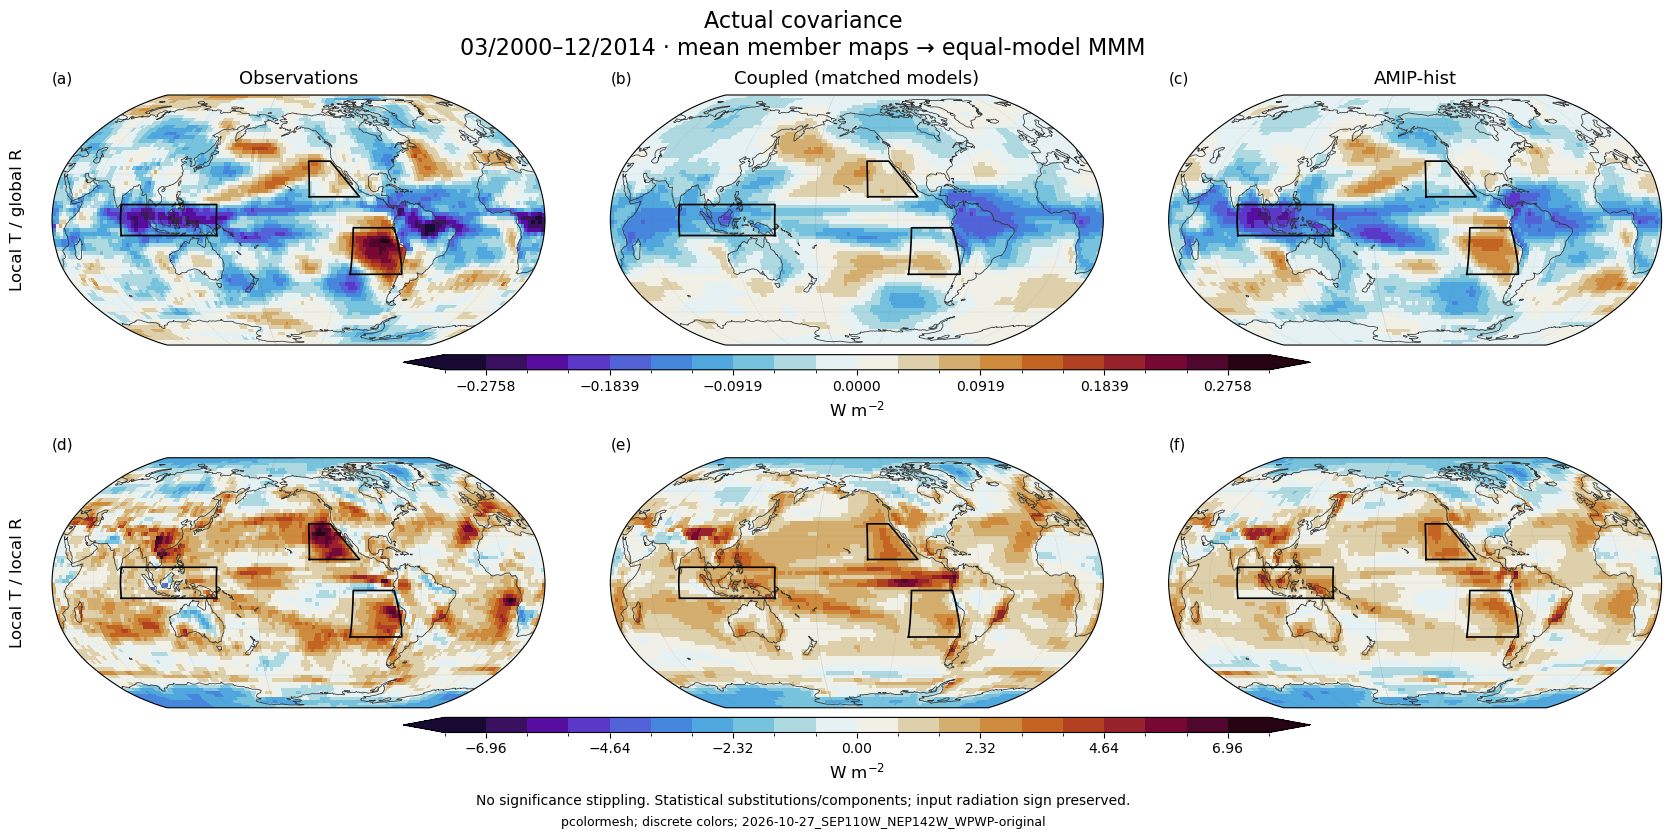

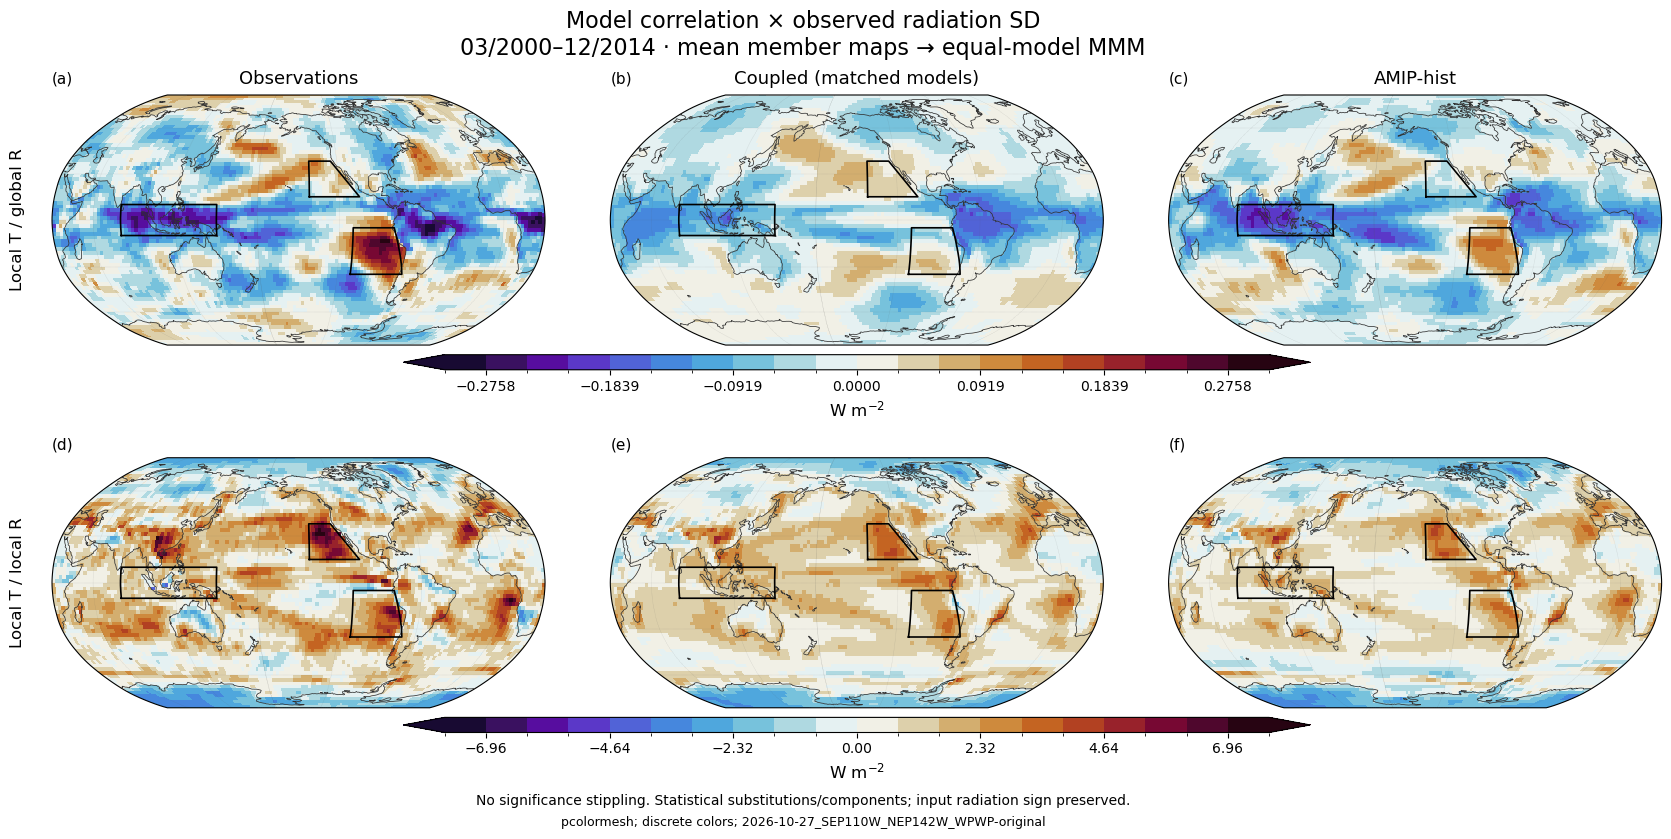

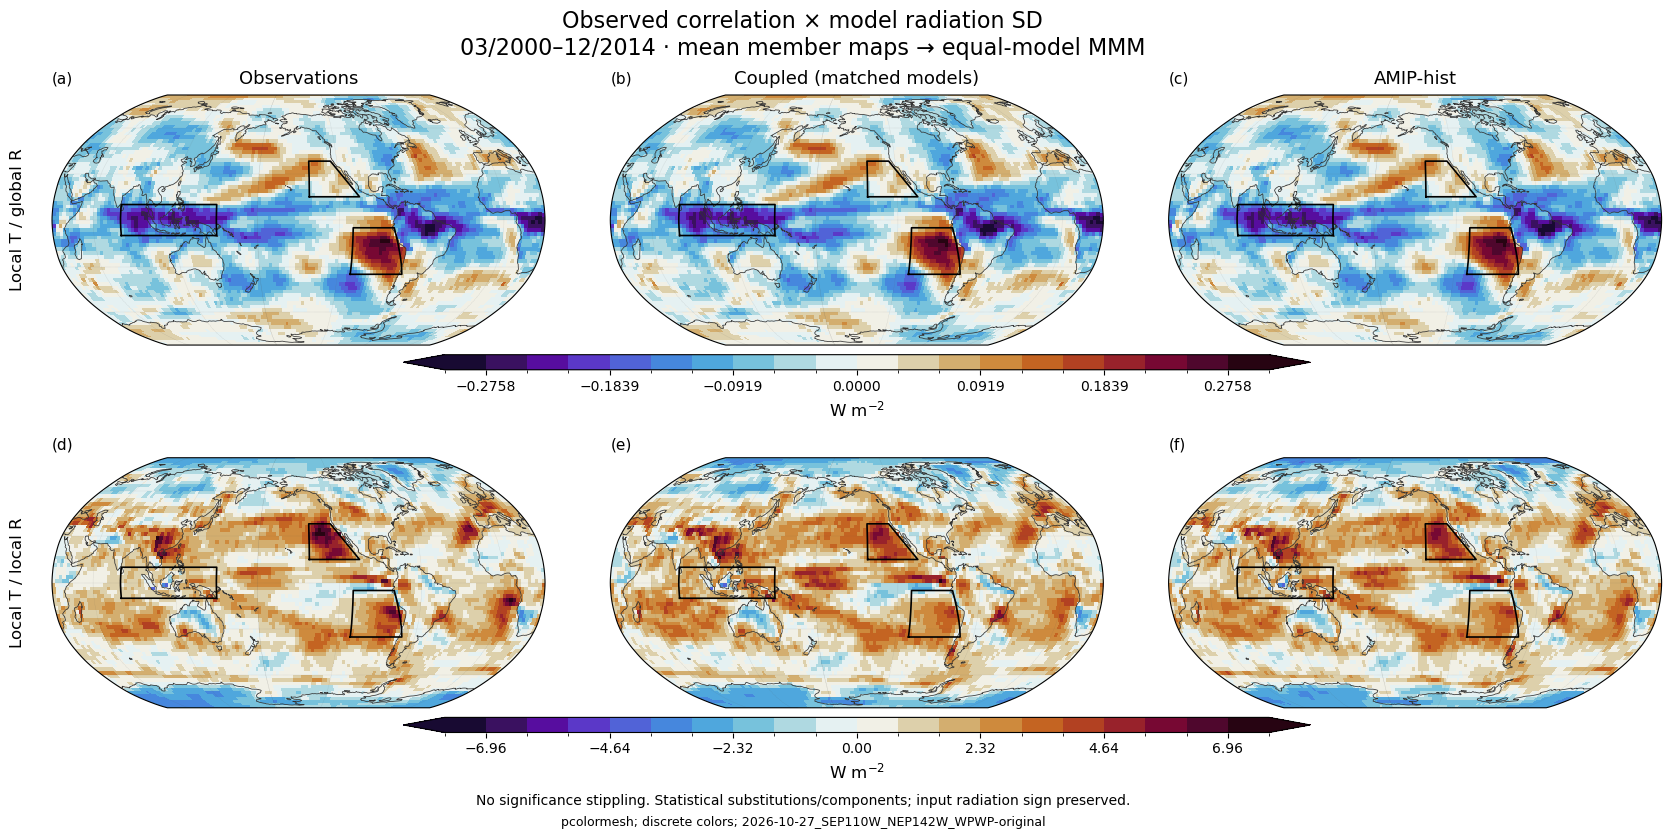

In [12]:
# 10. Compare actual covariance and the two substitutions in the Figure 1 layout
# One row per radiation family; columns are observations, matched historical, AMIP.
# All three figures use the SAME family-specific bounds, selected from every case.
actual_substitution_limits = []
for family_index, family in enumerate(families):
    maps = np.stack([separation_observations[family + '_actual']] +
                    [separation_MMM[exp][family + '_' + case] for exp in diagnostic_model_names for case in substitution_cases])
    finite = np.abs(maps[:, comparison_mask])
    finite = finite[np.isfinite(finite)]
    automatic = float(finite.max()) if finite.size and finite.max() > 0 else 1.
    chosen = None if substitution_vlims is None else substitution_vlims[family_index]
    actual_substitution_limits.append(automatic if chosen is None else chosen)
substitution_titles = {'actual': 'Actual covariance',
                       'observed_R_SD': 'Model correlation × observed radiation SD',
                       'observed_correlation': 'Observed correlation × model radiation SD'}
substitution_figures, substitution_axes = {}, {}
for case in substitution_cases:
    maps = np.stack([np.stack([separation_observations[family + '_' + case],
                     separation_MMM['historical_matched'][family + '_' + case],
                     separation_MMM['amip_hist'][family + '_' + case]]) for family in families])
    path = results_dir / 'figures' / ('substitution_' + case + '.png') if save_figures else None
    fig, axes, limits = plot_separation_grid(maps, [info['label'] for info in families.values()],
        ['Observations', 'Coupled (matched models)', 'AMIP-hist'], ['W m$^{-2}$', 'W m$^{-2}$'],
        substitution_titles[case], coordinates=diagnostic_coordinates, regions=diagnostic_regions,
        display_mask=comparison_mask, vlims=actual_substitution_limits, plot_method=plot_method,
        color_binning=color_binning, cmap=cmap_name, central_longitude=central_longitude,
        show_regions=show_regions, savepath=path, overwrite=overwrite, dpi=figure_dpi)
    substitution_figures[case], substitution_axes[case] = fig, axes
    plt.show()

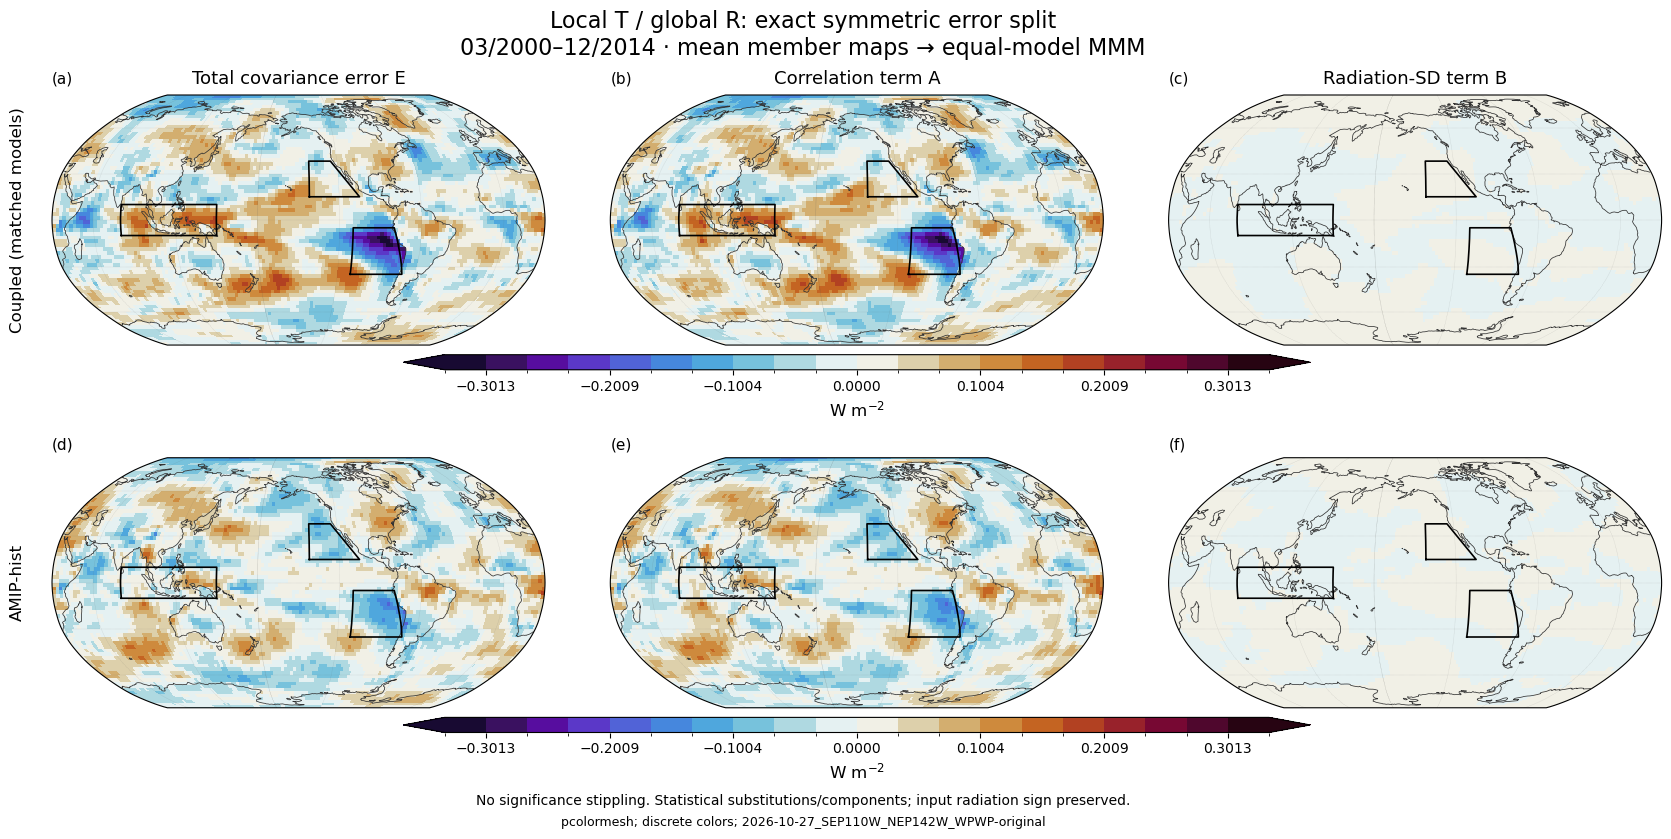

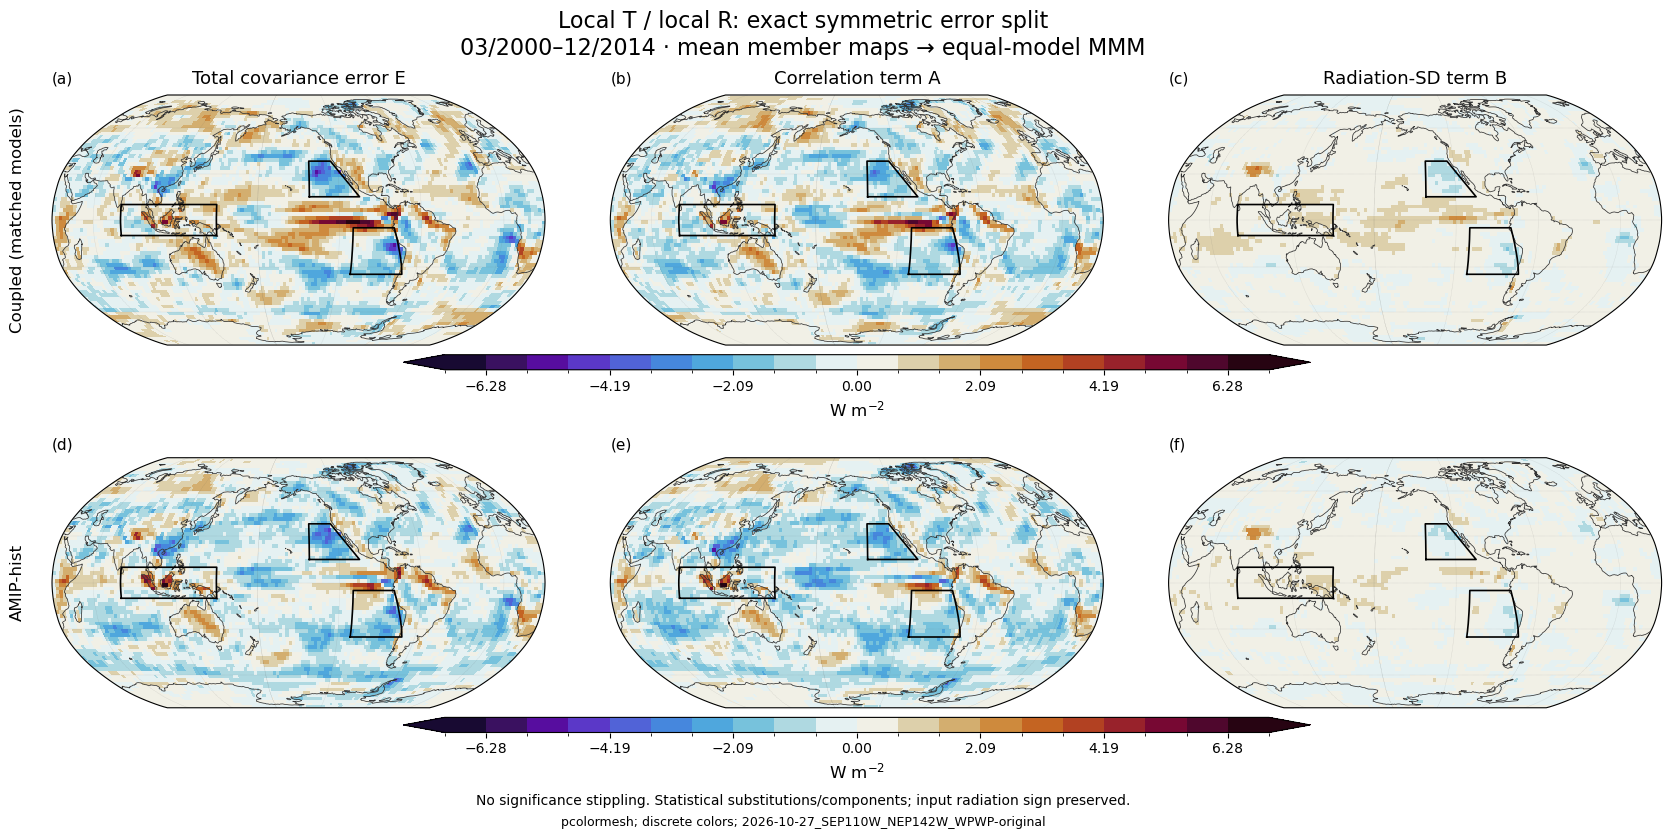

In [13]:
# 11. Show signed error components; columns add as first = second + third
# Maps show MEAN signed member errors/components, not mean squared errors.
# A small MMM error can coexist with appreciable errors in individual members.
component_figures, component_axes = {}, {}
for family, info in families.items():
    maps = np.stack([np.stack([separation_MMM[exp][family + '_' + case] for case in component_cases])
                     for exp in ['historical_matched', 'amip_hist']])
    finite = np.abs(maps[:, :, comparison_mask])
    finite = finite[np.isfinite(finite)]
    limit = float(finite.max()) if finite.size and finite.max() > 0 else 1.
    path = results_dir / 'figures' / ('error_components_' + family + '.png') if save_figures else None
    fig, axes, limits = plot_separation_grid(maps, ['Coupled (matched models)', 'AMIP-hist'],
        ['Total covariance error E', 'Correlation term A', 'Radiation-SD term B'],
        ['W m$^{-2}$', 'W m$^{-2}$'], info['label'] + ': exact symmetric error split',
        coordinates=diagnostic_coordinates, regions=diagnostic_regions, display_mask=comparison_mask,
        vlims=[limit, limit], plot_method=plot_method, color_binning=color_binning, cmap=cmap_name,
        central_longitude=central_longitude, show_regions=show_regions, savepath=path,
        overwrite=overwrite, dpi=figure_dpi)
    component_figures[family], component_axes[family] = fig, axes
    plt.show()

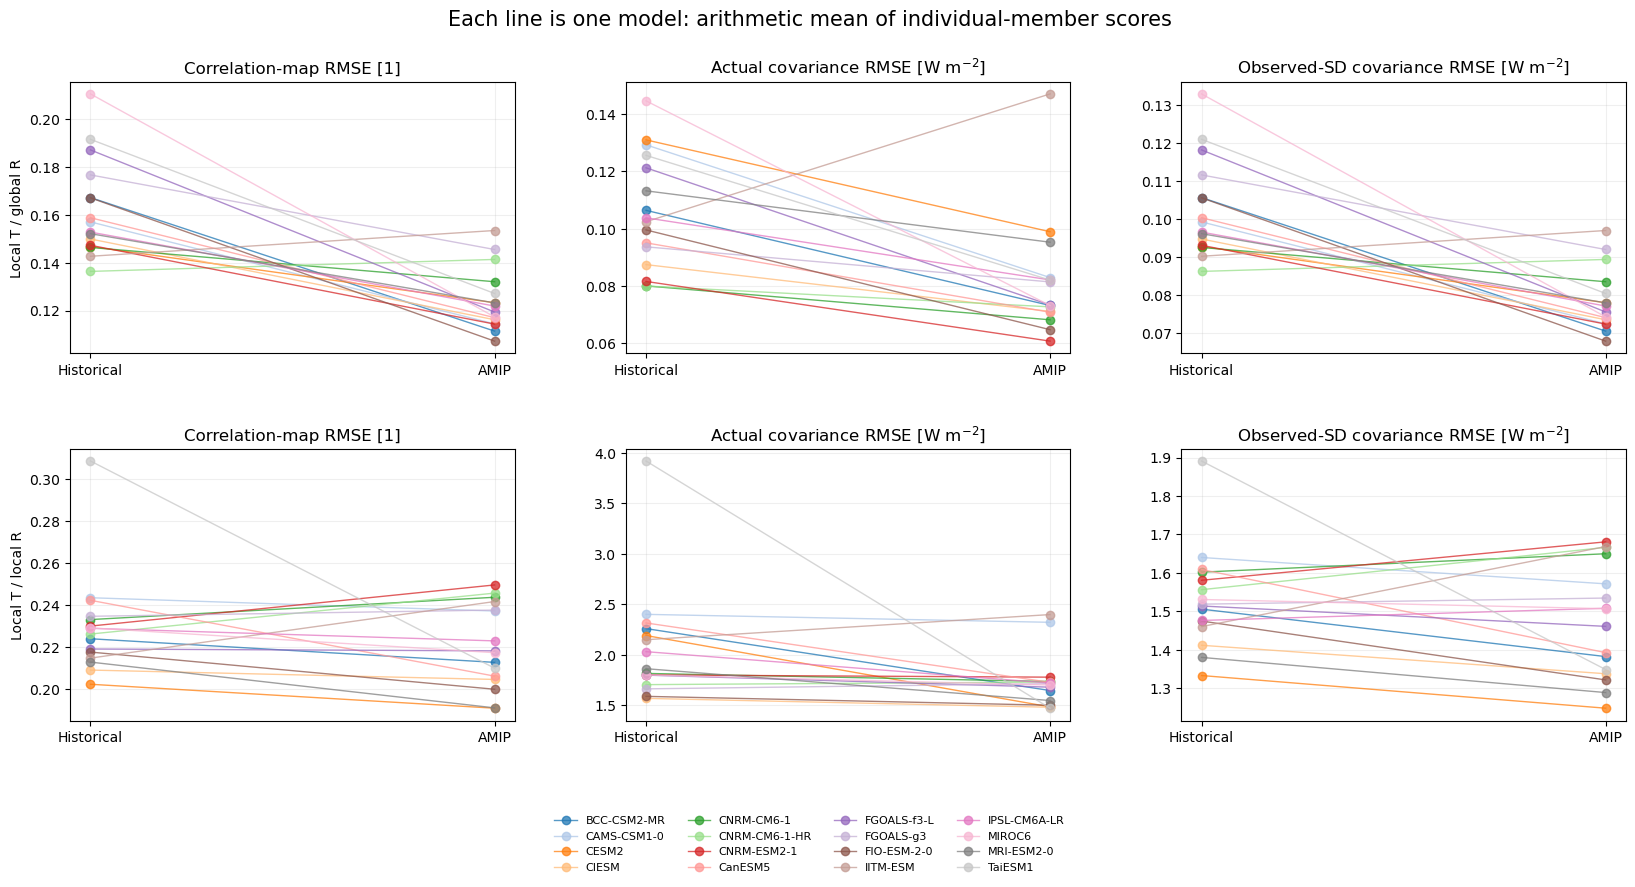

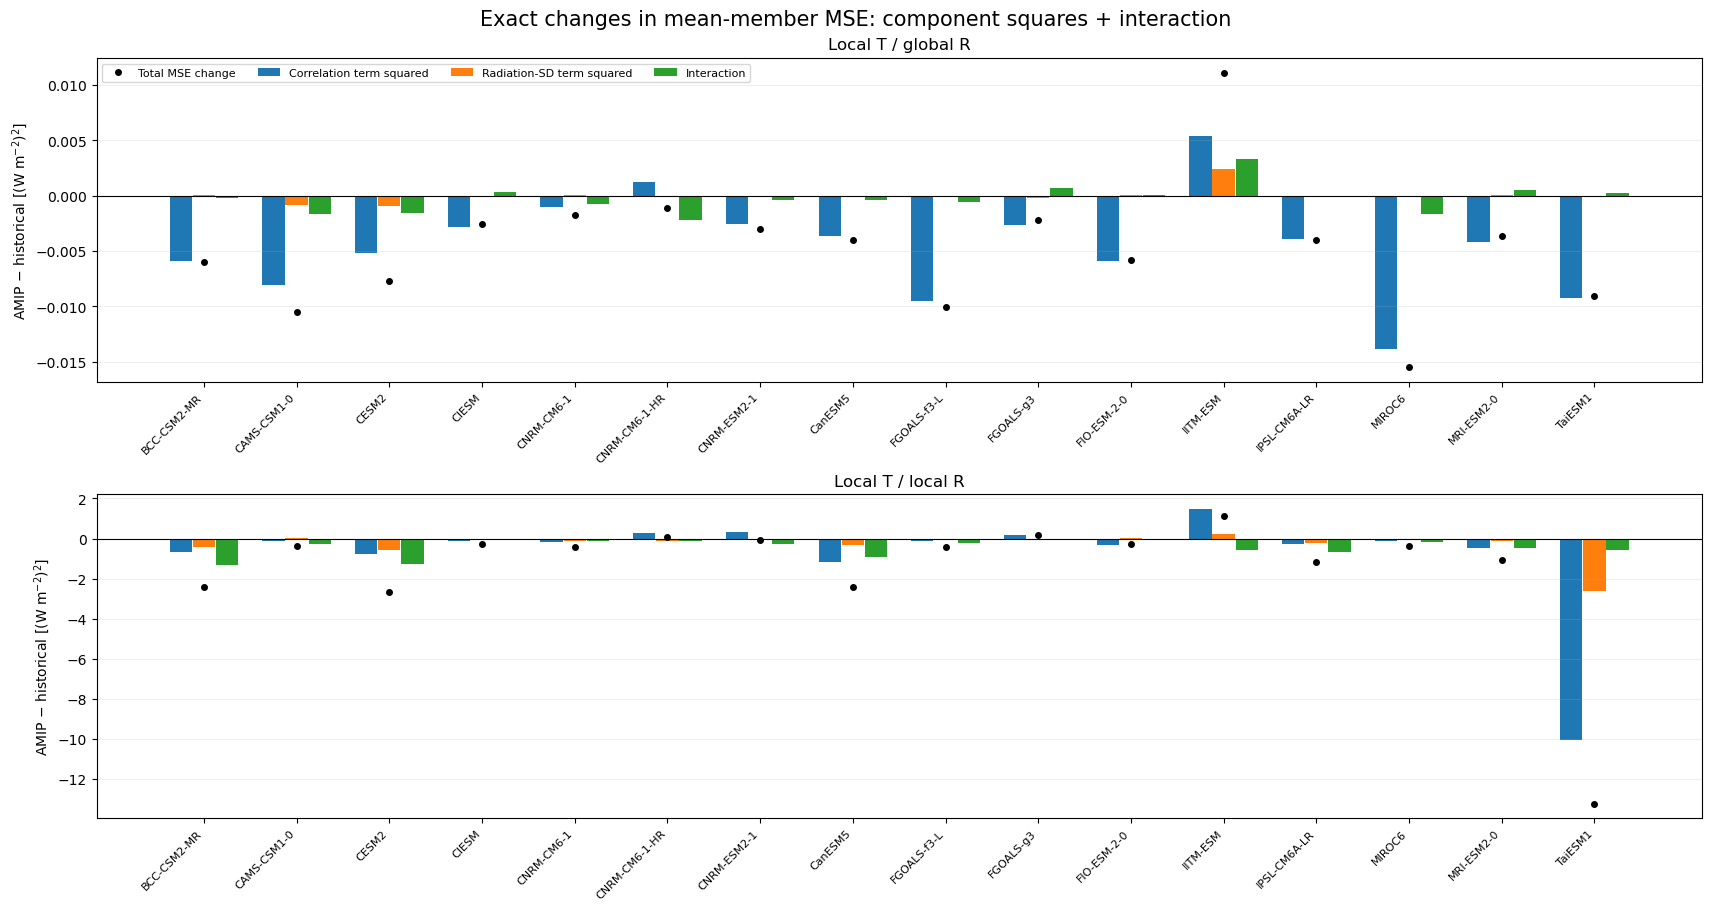

,experiment,family,mean_member_RMSE,MMM_field_RMSE
0,historical_matched,global_R,0.105887,0.064725
1,historical_matched,local_R,2.051949,1.182837
2,amip_hist,global_R,0.081110,0.050609
3,amip_hist,local_R,1.724094,1.100820


In [14]:
# 12. Plot member-first score changes and the MSE budgets
# The global observed-SD substitution is just correlation error in physical units:
# RMSE(rho_model*s_obs, rho_obs*s_obs) = s_obs*RMSE(rho_model,rho_obs).
# Locally, s_obs is a MAP, so it spatially weights correlation errors instead.
model_colors = {model: plt.get_cmap('tab20')(index % 20)
                for index, model in enumerate(diagnostic_model_names['amip_hist'])}
fig_scores, axes_scores = plt.subplots(2, 3, figsize=(17, 9))
fig_scores.subplots_adjust(left=0.065, right=0.98, top=0.90, bottom=0.19, hspace=0.35, wspace=0.25)
for row, (family, info) in enumerate(families.items()):
    for column, (case, title) in enumerate([('correlation', 'Correlation-map RMSE [1]'),
                                            ('actual', 'Actual covariance RMSE [W m$^{-2}$]'),
                                            ('observed_R_SD', 'Observed-SD covariance RMSE [W m$^{-2}$]')]):
        ax = axes_scores[row, column]
        subset = paired_change_table[(paired_change_table.quantity == family + '_' + case)
                                     & (paired_change_table.metric == 'rmse')]
        for _, value in subset.iterrows():
            ax.plot([0, 1], [value.historical, value.amip], marker='o', linewidth=1, alpha=0.75,
                    color=model_colors[value.model], label=value.model)
        ax.set_xticks([0, 1], ['Historical', 'AMIP'])
        ax.set_title(title)
        ax.grid(alpha=0.2)
        if column == 0:
            ax.set_ylabel(info['label'])
handles, labels = axes_scores[0, 0].get_legend_handles_labels()
fig_scores.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=4, fontsize=8, frameon=False)
fig_scores.suptitle('Each line is one model: arithmetic mean of individual-member scores', fontsize=15)
if save_figures:
    path = results_dir / 'figures' / 'member_first_substitution_scores.png'
    if path.exists() and not overwrite:
        raise FileExistsError(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig_scores.savefig(path, dpi=figure_dpi, bbox_inches='tight')
plt.show()

# Bars are changes in the three MSE terms; the black point is their sum.
# Negative total means AMIP improves. Negative interaction can mean cancellation.
fig_budget, axes_budget = plt.subplots(2, 1, figsize=(17, 9), constrained_layout=True)
for ax, (family, info) in zip(axes_budget, families.items()):
    table = budget_change_table[budget_change_table.family == family].set_index('model').reindex(diagnostic_model_names['amip_hist'])
    x = np.arange(len(table))
    for offset, key, label in [(-0.25, 'correlation_squared', 'Correlation term squared'),
                                (0., 'radiation_SD_squared', 'Radiation-SD term squared'),
                                (0.25, 'interaction', 'Interaction')]:
        ax.bar(x + offset, table[key], width=0.24, label=label)
    ax.plot(x, table['total_MSE'], 'ko', markersize=4, label='Total MSE change')
    ax.axhline(0., color='black', linewidth=0.8)
    ax.set_xticks(x, table.index, rotation=45, ha='right', fontsize=8)
    ax.set_title(info['label'])
    ax.set_ylabel(r'AMIP $-$ historical [(W m$^{-2}$)$^2$]')
    ax.grid(axis='y', alpha=0.2)
axes_budget[0].legend(ncol=4, fontsize=8)
fig_budget.suptitle('Exact changes in mean-member MSE: component squares + interaction', fontsize=15)
if save_figures:
    path = results_dir / 'figures' / 'MSE_budget_changes.png'
    if path.exists() and not overwrite:
        raise FileExistsError(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig_budget.savefig(path, dpi=figure_dpi, bbox_inches='tight')
plt.show()

# Keep the MMM-field comparison explicit; it is different from member performance.
display(pd.DataFrame([{'experiment': exp, 'family': family,
                      'mean_member_RMSE': separation_MMM_mean_member_scores[exp][family + '_actual']['rmse'],
                      'MMM_field_RMSE': separation_MMM_scores[exp][family + '_actual']['rmse']}
                     for exp in diagnostic_model_names for family in families]))